# 02. 전처리 — PROTOCOL.md 2절 구현 확인

학습 데이터만 사용한다. 코드는 `src/preprocess.py`, 검증은 `tests/test_preprocess.py`.

| 단계 | 로지스틱 회귀 | LightGBM |
|---|---|---|
| 결측 지시자 | 옵션 (03에서 교차검증으로 결정) | 옵션 |
| 고결측 센서 | 결측률 50% 초과 제거 | 제거 |
| 결측 대체 | 중앙값 | 하지 않음 |
| 상수 센서 | 제거 | 제거 |
| 극단값 | 0.5% ~ 99.5% 분위수로 자르기 | 하지 않음 |
| 스케일 | 표준화 | 하지 않음 |

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.data import load_train

sns.set_theme(style="whitegrid")
REPORT_DIR = ROOT / "reports"
FIG_DIR = REPORT_DIR / "figures"
X, y, ts = load_train()

from src.preprocess import build_linear_preprocessor, build_tree_preprocessor

## 1. 단계별 센서 수

In [2]:
linear = build_linear_preprocessor().fit(X)
counts, out = [("원본", X.shape[1])], X
for name, step in linear.steps:
    if step == "passthrough":
        continue
    out = step.transform(out)
    counts.append((name, out.shape[1]))
table = pd.DataFrame(counts, columns=["단계", "센서 수"])
table["제거"] = (-table["센서 수"].diff()).fillna(0).astype(int)
table

,단계,센서 수,제거
0,원본,590,0
1,drop_missing,566,24
2,impute,566,0
3,drop_constant,444,122
4,clip,444,0
5,scale,444,0


**해석**: 590개 중 결측 50% 초과 24개, 상수 122개가 빠져 **444개**가 남는다. EDA 숫자와 같다.

## 2. 센서 오류값 처리

In [3]:
clip = linear.named_steps["clip"]
examples = ["sensor_204", "sensor_340", "sensor_067"]
pd.DataFrame({
    "중앙값": X[examples].median(),
    "99% 분위수": X[examples].quantile(0.99),
    "원래 최댓값": X[examples].max(),
    "자르는 상한 (99.5%)": clip.high_[examples],
}).round(4)

,중앙값,99% 분위수,원래 최댓값,자르는 상한 (99.5%)
sensor_204,0.1666,0.7539,9997.8983,0.8922
sensor_340,0.0498,0.2292,5043.8789,0.2828
sensor_067,1.0078,1.5482,7272.8283,1.7724


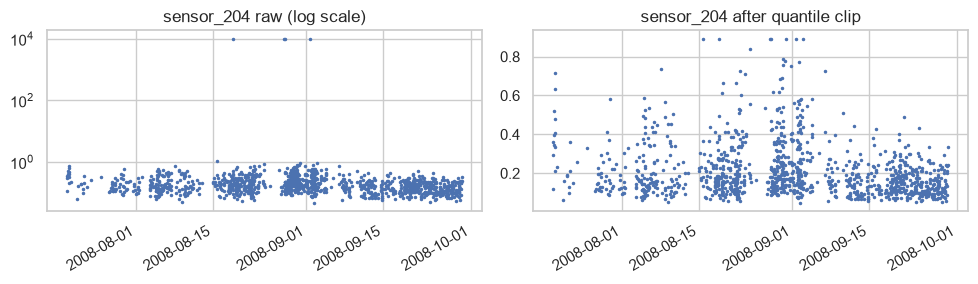

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharex=True)
raw = X["sensor_204"]
capped = raw.clip(upper=clip.high_["sensor_204"])
axes[0].plot(ts, raw, ".", ms=3); axes[0].set_yscale("log"); axes[0].set_title("sensor_204 raw (log scale)")
axes[1].plot(ts, capped, ".", ms=3); axes[1].set_title("sensor_204 after quantile clip")
fig.autofmt_xdate(); fig.tight_layout()
fig.savefig(FIG_DIR / "06_clip_example.png", dpi=150)

**해석**: 9998 같은 값은 99.5% 분위수(0.89)로 바뀌고, 나머지 값은 그대로다.
최솟값~최댓값으로 잘랐다면 최댓값이 9998이라 아무것도 바뀌지 않았을 것이다.

## 3. 결과 확인

In [5]:
Z = linear.transform(X)
tree = build_tree_preprocessor().fit(X)
T = tree.transform(X)
pd.DataFrame({
    "로지스틱용": [Z.shape[1], int(Z.isna().sum().sum()), round(Z.abs().max().max(), 1)],
    "LightGBM용": [T.shape[1], int(T.isna().sum().sum()), round(T.abs().max().max(), 1)],
}, index=["센서 수", "결측 셀", "절댓값 최대"])

,로지스틱용,LightGBM용
센서 수,444.0,444.0
결측 셀,0.0,9921.0
절댓값 최대,11.9,37943.0


In [6]:
with_flags = build_linear_preprocessor(add_indicator=True).fit_transform(X)
flags = [c for c in with_flags.columns if c.endswith("_isna")]
print(f"결측 지시자를 켜면 {len(flags)}개 열 추가 → {with_flags.shape[1]}개")

결측 지시자를 켜면 52개 열 추가 → 496개


**해석**
- 로지스틱용: 결측 0, 표준화 후 절댓값 최대 약 12. 오류값(표준화하면 수천)이 사라졌다.
- LightGBM용: 결측과 원래 값을 그대로 둔다. 트리는 대소 비교만 하므로 9998도 "가장 큰 쪽" 가지로 갈 뿐이다.
- 결측 지시자를 켜면 52개 열이 추가된다. 켤지 말지는 03에서 교차검증으로 정한다.